In [1]:
import numpy as np
import pandas as pd

df = pd.read_csv('movie_reviews.csv').rename(columns={'review': 'text', 'sentiment': 'label'})
print("Raw shape:", df.shape)

df = df.drop_duplicates(subset='text')
df['text'] = df['text'].str.replace('<br />', ' ', regex=False)
df = df.reset_index(drop=True)

print("After dropping duplicates:", df.shape)
print(df['label'].value_counts())
df.head()

Raw shape: (50000, 2)
After dropping duplicates: (49582, 2)
label
positive    24884
negative    24698
Name: count, dtype: int64


,text,label
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. The filming t...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


## Activity 1: Bag-of-Words with `CountVectorizer`

In [2]:
from sklearn.feature_extraction.text import CountVectorizer

bow_vectorizer = CountVectorizer()
X_bow = bow_vectorizer.fit_transform(df['text'])

print("Vocabulary size:", len(bow_vectorizer.vocabulary_))
print("Matrix shape (docs x vocab):", X_bow.shape)
print("Sparsity: {:.2%} of entries are zero".format(1 - X_bow.nnz / (X_bow.shape[0]*X_bow.shape[1])))

print("\nSparse matrix portion (first 5 docs, first 10 features):")
terms = bow_vectorizer.get_feature_names_out()[:10]
print(pd.DataFrame(X_bow[:5, :10].toarray(), columns=terms))

Vocabulary size: 101895
Matrix shape (docs x vocab): (49582, 101895)
Sparsity: 99.87% of entries are zero

Sparse matrix portion (first 5 docs, first 10 features):
   00  000  00000000000  0000000000001  00000001  00001  00015  000dm  000s  \
0   0    0            0              0         0      0      0      0     0   
1   0    0            0              0         0      0      0      0     0   
2   0    0            0              0         0      0      0      0     0   
3   0    0            0              0         0      0      0      0     0   
4   0    0            0              0         0      0      0      0     0   

   001  
0    0  
1    0  
2    0  
3    0  
4    0  


## Activity 2: TF-IDF vs. raw counts
We choose the two most widespread words that occur in the chosen document, and look each word up in **its own vectorizer's vocabulary** (the two vectorizers are separate objects, so column indices aren't guaranteed to match).

In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer()
X_tfidf_full = tfidf_vectorizer.fit_transform(df['text'])   # exploration only, not used for modelling

doc_id = 1
doc_freq = np.asarray((X_bow > 0).sum(axis=0)).ravel()
bow_vocab, tfidf_vocab = bow_vectorizer.vocabulary_, tfidf_vectorizer.vocabulary_

bow_terms = bow_vectorizer.get_feature_names_out()
cols_in_doc = X_bow[doc_id].nonzero()[1]
top_cols = sorted(cols_in_doc, key=lambda c: -doc_freq[c])[:2]
word1, word2 = bow_terms[top_cols[0]], bow_terms[top_cols[1]]

print(f"Document {doc_id}: '{df['text'].iloc[doc_id][:300]}...'\n")
for w in (word1, word2):
    raw_c = X_bow[doc_id, bow_vocab[w]]
    tfidf = X_tfidf_full[doc_id, tfidf_vocab[w]]
    print(f"'{w}' (in {doc_freq[bow_vocab[w]]:,}/{len(df):,} reviews) -> Raw count: {raw_c}, TF-IDF: {tfidf:.4f}")

print("\nExplanation: the TF-IDF weight is lower because words found in almost every review get an IDF "
      "= log(N/DF) near zero, which suppresses them regardless of how often they occur in this document "
      "(sklearn also L2-normalises each row).")

Document 1: 'A wonderful little production.   The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometimes discomforting, sense of realism to the entire piece.   The actors are extremely well chosen- Michael Sheen not only "has got all the polari" but he has all the v...'

'the' (in 49,144/49,582 reviews) -> Raw count: 16, TF-IDF: 0.2693
'and' (in 47,902/49,582 reviews) -> Raw count: 7, TF-IDF: 0.1208

Explanation: the TF-IDF weight is lower because words found in almost every review get an IDF = log(N/DF) near zero, which suppresses them regardless of how often they occur in this document (sklearn also L2-normalises each row).


## Activity 3: Train/test split, Naive Bayes and Logistic Regression
We split the raw text first, fit TF-IDF on the training text only, and just `transform` the test text, which avoids data leakage.

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

X_train_text, X_test_text, y_train, y_test = train_test_split(
    df['text'], df['label'], test_size=0.2, random_state=42
)

tfidf = TfidfVectorizer()
X_train = tfidf.fit_transform(X_train_text)   # fit on train only
X_test  = tfidf.transform(X_test_text)

nb_model = MultinomialNB().fit(X_train, y_train)
nb_preds = nb_model.predict(X_test)

lr_model = LogisticRegression(max_iter=1000).fit(X_train, y_train)
lr_preds = lr_model.predict(X_test)
print("Train size:", X_train.shape[0], "| Test size:", X_test.shape[0])

Train size: 39665 | Test size: 9917


## Activity 4: Evaluation (accuracy, precision, recall, F1, confusion matrix)

--- Naive Bayes ---
Accuracy:  0.8636
Precision: 0.8767
Recall:    0.8473
F1-Score:  0.8618
Confusion Matrix (rows=true, cols=pred; order Neg, Pos):
[[4346  593]
 [ 760 4218]]

--- Logistic Regression ---
Accuracy:  0.8954
Precision: 0.8834
Recall:    0.9120
F1-Score:  0.8975
Confusion Matrix (rows=true, cols=pred; order Neg, Pos):
[[4340  599]
 [ 438 4540]]



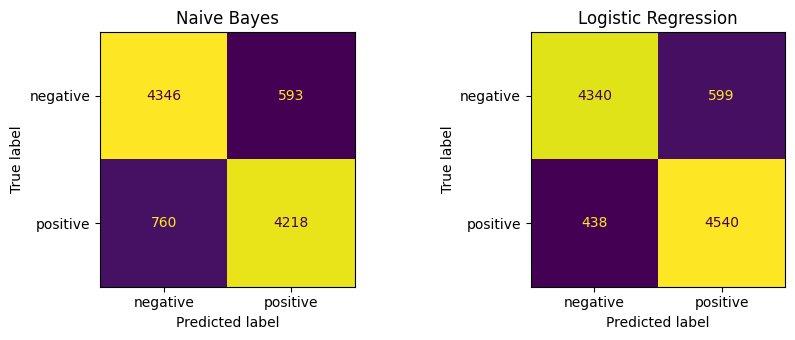

,accuracy,precision,recall,f1
model,,,,
Naive Bayes,0.8636,0.8767,0.8473,0.8618
Logistic Regression,0.8954,0.8834,0.9120,0.8975


In [5]:
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)

POS, NEG = 'positive', 'negative'

def evaluate_and_print(model_name, y_true, y_pred):
    acc  = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, pos_label=POS)
    rec  = recall_score(y_true, y_pred, pos_label=POS)
    f1   = f1_score(y_true, y_pred, pos_label=POS)
    cm   = confusion_matrix(y_true, y_pred, labels=[NEG, POS])
    print(f"--- {model_name} ---")
    print(f"Accuracy:  {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall:    {rec:.4f}")
    print(f"F1-Score:  {f1:.4f}")
    print(f"Confusion Matrix (rows=true, cols=pred; order Neg, Pos):\n{cm}\n")
    return {'model': model_name, 'accuracy': acc, 'precision': prec, 'recall': rec, 'f1': f1, 'cm': cm}

results = [evaluate_and_print("Naive Bayes", y_test, nb_preds),
           evaluate_and_print("Logistic Regression", y_test, lr_preds)]

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for ax, r in zip(axes, results):
    ConfusionMatrixDisplay(r['cm'], display_labels=[NEG, POS]).plot(ax=ax, colorbar=False, values_format='d')
    ax.set_title(r['model'])
plt.tight_layout(); plt.show()

pd.DataFrame(results).drop(columns='cm').set_index('model').round(4)

## Activity 5: Pipeline + classifying brand-new reviews

In [6]:
import os
from sklearn.pipeline import Pipeline

best_name = max(results, key=lambda r: r['f1'])['model']
print("Better model by F1:", best_name)
best_clf = MultinomialNB() if best_name == "Naive Bayes" else LogisticRegression(max_iter=1000)

pipeline = Pipeline([('tfidf', TfidfVectorizer()), ('clf', best_clf)])
pipeline.fit(X_train_text, y_train)
print("Pipeline test accuracy:", round(pipeline.score(X_test_text, y_test), 4), "\n")

# new_reviews.txt (one review per line). Created with samples if missing, so predictions always run.
if not os.path.exists('new_reviews.txt'):
    print("'new_reviews.txt' not found -> creating it with three sample reviews.\n")
    with open('new_reviews.txt', 'w') as f:
        f.write("An absolutely brilliant film with superb acting and a moving story.\n"
                "A boring, predictable mess. The plot made no sense and I wanted my money back.\n"
                "Not bad, but the second half dragged and the ending was disappointing.\n")

with open('new_reviews.txt') as f:
    new_reviews = [line.strip() for line in f if line.strip()]
if not new_reviews:
    print("WARNING: new_reviews.txt is empty - no predictions made.")

for review, pred in zip(new_reviews, pipeline.predict(new_reviews)):
    print(f"Review: {review}\nPrediction: {pred}\n")

Better model by F1: Logistic Regression
Pipeline test accuracy: 0.8954 

'new_reviews.txt' not found -> creating it with three sample reviews.

Review: An absolutely brilliant film with superb acting and a moving story.
Prediction: positive

Review: A boring, predictable mess. The plot made no sense and I wanted my money back.
Prediction: negative

Review: Not bad, but the second half dragged and the ending was disappointing.
Prediction: negative



## Bonus (Stage v): class imbalance
This dataset is balanced, so to see the problem we **artificially** keep only ~5% of the negative reviews and treat **negative** as the class we care about. A model that always predicts `positive` would score ~95% accuracy while catching no negative reviews.

In [7]:
pos_df = df[df.label == POS]
neg_df = df[df.label == NEG].sample(n=len(pos_df)//19, random_state=42)
imb = pd.concat([pos_df, neg_df]).sample(frac=1, random_state=42).reset_index(drop=True)
print(imb['label'].value_counts(), "\n")
print("Always-predict-'positive' accuracy: {:.3f}\n".format((imb.label == POS).mean()))

Xtr, Xte, ytr, yte = train_test_split(imb['text'], imb['label'], test_size=0.2,
                                      random_state=42, stratify=imb['label'])

def run(cw):
    p = Pipeline([('tfidf', TfidfVectorizer()), ('clf', LogisticRegression(class_weight=cw, max_iter=1000))])
    p.fit(Xtr, ytr); pr = p.predict(Xte)
    return {'class_weight': str(cw),
            'accuracy': accuracy_score(yte, pr),
            'precision(neg)': precision_score(yte, pr, pos_label=NEG, zero_division=0),
            'recall(neg)': recall_score(yte, pr, pos_label=NEG, zero_division=0),
            'f1(neg)': f1_score(yte, pr, pos_label=NEG, zero_division=0)}

pd.DataFrame([run(None), run('balanced')]).set_index('class_weight').round(4)

label
positive    24884
negative     1309
Name: count, dtype: int64 

Always-predict-'positive' accuracy: 0.950



,accuracy,precision(neg),recall(neg),f1(neg)
class_weight,,,,
None,0.9544,0.9600,0.0916,0.1672
balanced,0.9483,0.4872,0.6527,0.5579


**Takeaway:** judge by `recall(neg)` and `f1(neg)`, not accuracy. `class_weight='balanced'` re-weights the loss by inverse class frequency so the minority class is not ignored.